## Environmental and Vector Analysis Pipeline
### Correlation between climate and *An. gambiae* abundance in Greater Accra, Ghana

#### 1. Setup and Imports

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
import geopandas as gpd
from shapely import wkt
import contextily as ctx
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.append(str(project_root))

from database.session import engine
from database.models import Location, VectorObservation, EnvironmentalFactor

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

#### 2. Data Loading and Preprocessing

In [2]:
def load_vector_data():
    """Load and spatially filter vector observation data."""
    query_vec = """
    SELECT 
        v.date_id,
        v.location_code,
        v.vector_species,
        v.count,
        l.centroid_lat AS lat,
        l.centroid_lon AS lon,
        l.geometry_wkt AS geom_wkt
    FROM vector_observation v
    JOIN location l ON v.location_code = l.location_code
    WHERE v.vector_species LIKE '%gambiae%'
    """
    
    df_vec = pd.read_sql(query_vec, engine)
    print(f"Total vector observations (all sites): {len(df_vec)}")
    
    # Convert to GeoDataFrame
    gdf_points = gpd.GeoDataFrame(
        df_vec,
        geometry=gpd.points_from_xy(df_vec['lon'], df_vec['lat']),
        crs='EPSG:4326'
    )
    
    # Load region polygon
    query_region = """
    SELECT geometry_wkt FROM location 
    WHERE name = 'Greater Accra' AND admin_level = 'region'
    """
    accra_wkt = pd.read_sql(query_region, engine).iloc[0, 0]
    accra_polygon = wkt.loads(accra_wkt)
    gdf_region = gpd.GeoDataFrame({'geometry': [accra_polygon]}, crs='EPSG:4326')
    
    # Spatial filter
    gdf_accra = gdf_points[gdf_points.within(gdf_region.unary_union)]
    print(f"Vector observations within Greater Accra: {len(gdf_accra)}")
    
    return gdf_accra

def load_environmental_data():
    """Load environmental data for Greater Accra."""
    query_env = """
    SELECT 
        date_id,
        temperature_mean,
        rainfall_total
    FROM environmental_factor
    WHERE location_code = 'greater_accra'
    ORDER BY date_id
    """
    
    df_env = pd.read_sql(query_env, engine)
    df_env['date'] = pd.to_datetime(df_env['date_id'])
    print(f"Environmental records: {len(df_env)} days")
    
    return df_env

# Load data
gdf_accra = load_vector_data()
df_env = load_environmental_data()


Total vector observations (all sites): 6312
Vector observations within Greater Accra: 6156
Environmental records: 732 days


#### 3. Temporal Aggregation and Analysis

In [12]:
def aggregate_to_monthly(gdf_accra, df_env):
    """Aggregate vector and environmental data to monthly resolution."""
    
    # Vector monthly aggregation
    df_vec_monthly = gdf_accra.groupby('date_id')['count'].agg(['sum', 'mean', 'std']).reset_index()
    df_vec_monthly.columns = ['date_id', 'total_count', 'mean_count', 'std_count']
    df_vec_monthly['date'] = pd.to_datetime(df_vec_monthly['date_id'])
    
    print(f"Monthly vector observations: {len(df_vec_monthly)} months")
    print("Vector date range:", df_vec_monthly['date_id'].min(), "to", df_vec_monthly['date_id'].max())
    
    # Environmental monthly aggregation
    numeric_cols = ['temperature_mean', 'rainfall_total']
    
    # Create a copy and set index properly
    df_env_indexed = df_env.set_index('date').copy()
    
    # Resample and aggregate
    df_env_monthly = df_env_indexed[numeric_cols].resample('ME').agg(['mean', 'std', 'min', 'max'])
    
    # Flatten column names
    df_env_monthly.columns = ['_'.join(col).strip() for col in df_env_monthly.columns.values]
    df_env_monthly = df_env_monthly.reset_index()
    df_env_monthly['date_id'] = df_env_monthly['date'].dt.strftime('%Y-%m-01')
    
    print(f"Monthly environmental records: {len(df_env_monthly)} months")
    print("Environmental date range:", df_env_monthly['date_id'].min(), "to", df_env_monthly['date_id'].max())
    
    # Merge datasets
    df_merged = pd.merge(
        df_vec_monthly,
        df_env_monthly,
        on='date_id',
        how='inner'
    )
    
    # Ensure date column exists (from vector data)
    if 'date' not in df_merged.columns:
        df_merged['date'] = pd.to_datetime(df_merged['date_id'])
    
    print(f"Overlapping months: {len(df_merged)}")
    print(f"Merged columns: {df_merged.columns.tolist()}")
    
    return df_merged

df_merged = aggregate_to_monthly(gdf_accra, df_env)


Monthly vector observations: 3 months
Vector date range: 2023-01-01 to 2025-01-01
Monthly environmental records: 25 months
Environmental date range: 2023-12-01 to 2025-12-01
Overlapping months: 2
Merged columns: ['date_id', 'total_count', 'mean_count', 'std_count', 'date_x', 'date_y', 'temperature_mean_mean', 'temperature_mean_std', 'temperature_mean_min', 'temperature_mean_max', 'rainfall_total_mean', 'rainfall_total_std', 'rainfall_total_min', 'rainfall_total_max', 'date']


#### 4. Exploratory Data Analysis

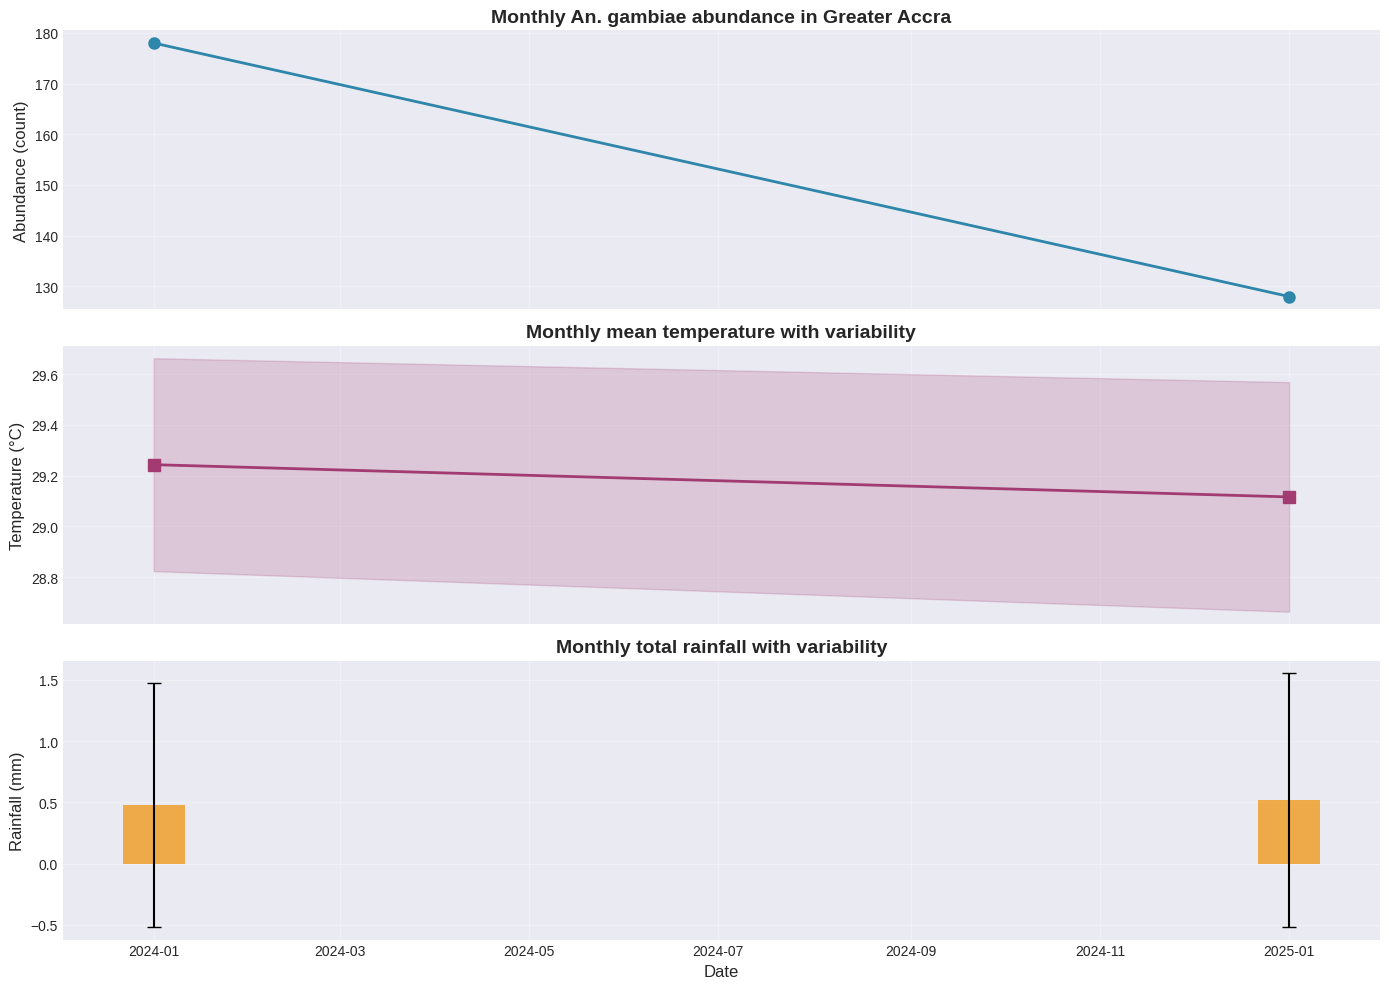

In [13]:
def plot_time_series(df_merged):
    """Create comprehensive time series visualization."""
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    
    # Abundance
    axes[0].plot(df_merged['date'], df_merged['total_count'], 
                 marker='o', linestyle='-', linewidth=2, markersize=8, color='#2E86AB')
    axes[0].fill_between(df_merged['date'], 
                          df_merged['total_count'] - df_merged['std_count'],
                          df_merged['total_count'] + df_merged['std_count'],
                          alpha=0.2, color='#2E86AB')
    axes[0].set_ylabel('Abundance (count)', fontsize=12)
    axes[0].set_title('Monthly An. gambiae abundance in Greater Accra', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # Temperature
    axes[1].plot(df_merged['date'], df_merged['temperature_mean_mean'], 
                 marker='s', linestyle='-', linewidth=2, markersize=8, color='#A23B72')
    axes[1].fill_between(df_merged['date'],
                          df_merged['temperature_mean_mean'] - df_merged['temperature_mean_std'],
                          df_merged['temperature_mean_mean'] + df_merged['temperature_mean_std'],
                          alpha=0.2, color='#A23B72')
    axes[1].set_ylabel('Temperature (°C)', fontsize=12)
    axes[1].set_title('Monthly mean temperature with variability', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # Rainfall
    axes[2].bar(df_merged['date'], df_merged['rainfall_total_mean'], 
                width=20, color='#F18F01', alpha=0.7, label='Mean rainfall')
    axes[2].errorbar(df_merged['date'], df_merged['rainfall_total_mean'],
                     yerr=df_merged['rainfall_total_std'],
                     fmt='none', color='black', capsize=5)
    axes[2].set_ylabel('Rainfall (mm)', fontsize=12)
    axes[2].set_title('Monthly total rainfall with variability', fontsize=14, fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    
    plt.xlabel('Date', fontsize=12)
    plt.tight_layout()
    plt.show()

plot_time_series(df_merged)


#### 5. Correlation Analysis

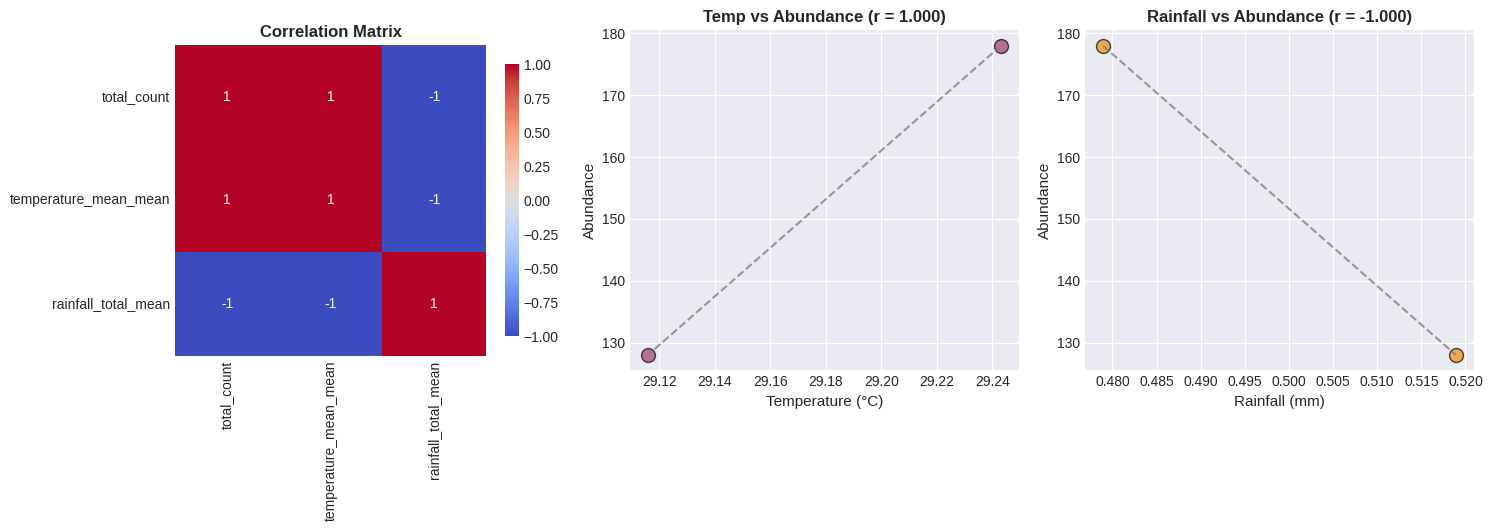

In [14]:
def analyze_correlations(df_merged):
    """Compute and visualize correlations between variables."""
    
    # Basic correlations
    corr_matrix = df_merged[['total_count', 'temperature_mean_mean', 'rainfall_total_mean']].corr()
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Correlation matrix heatmap
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
                square=True, ax=axes[0], cbar_kws={"shrink": 0.8})
    axes[0].set_title('Correlation Matrix', fontsize=12, fontweight='bold')
    
    # Temperature scatter
    axes[1].scatter(df_merged['temperature_mean_mean'], df_merged['total_count'], 
                    s=100, alpha=0.7, color='#A23B72', edgecolors='black')
    axes[1].set_xlabel('Temperature (°C)', fontsize=11)
    axes[1].set_ylabel('Abundance', fontsize=11)
    axes[1].set_title(f'Temp vs Abundance (r = {corr_matrix.loc["total_count", "temperature_mean_mean"]:.3f})', 
                      fontsize=12, fontweight='bold')
    
    # Add trend line
    z = np.polyfit(df_merged['temperature_mean_mean'], df_merged['total_count'], 1)
    p = np.poly1d(z)
    axes[1].plot(df_merged['temperature_mean_mean'], p(df_merged['temperature_mean_mean']), 
                 '--', color='gray', alpha=0.8)
    
    # Rainfall scatter
    axes[2].scatter(df_merged['rainfall_total_mean'], df_merged['total_count'],
                    s=100, alpha=0.7, color='#F18F01', edgecolors='black')
    axes[2].set_xlabel('Rainfall (mm)', fontsize=11)
    axes[2].set_ylabel('Abundance', fontsize=11)
    axes[2].set_title(f'Rainfall vs Abundance (r = {corr_matrix.loc["total_count", "rainfall_total_mean"]:.3f})',
                      fontsize=12, fontweight='bold')
    
    # Add trend line
    z = np.polyfit(df_merged['rainfall_total_mean'], df_merged['total_count'], 1)
    p = np.poly1d(z)
    axes[2].plot(df_merged['rainfall_total_mean'], p(df_merged['rainfall_total_mean']),
                 '--', color='gray', alpha=0.8)
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix

corr_matrix = analyze_correlations(df_merged)


#### 6. Lagged Correlation Analysis

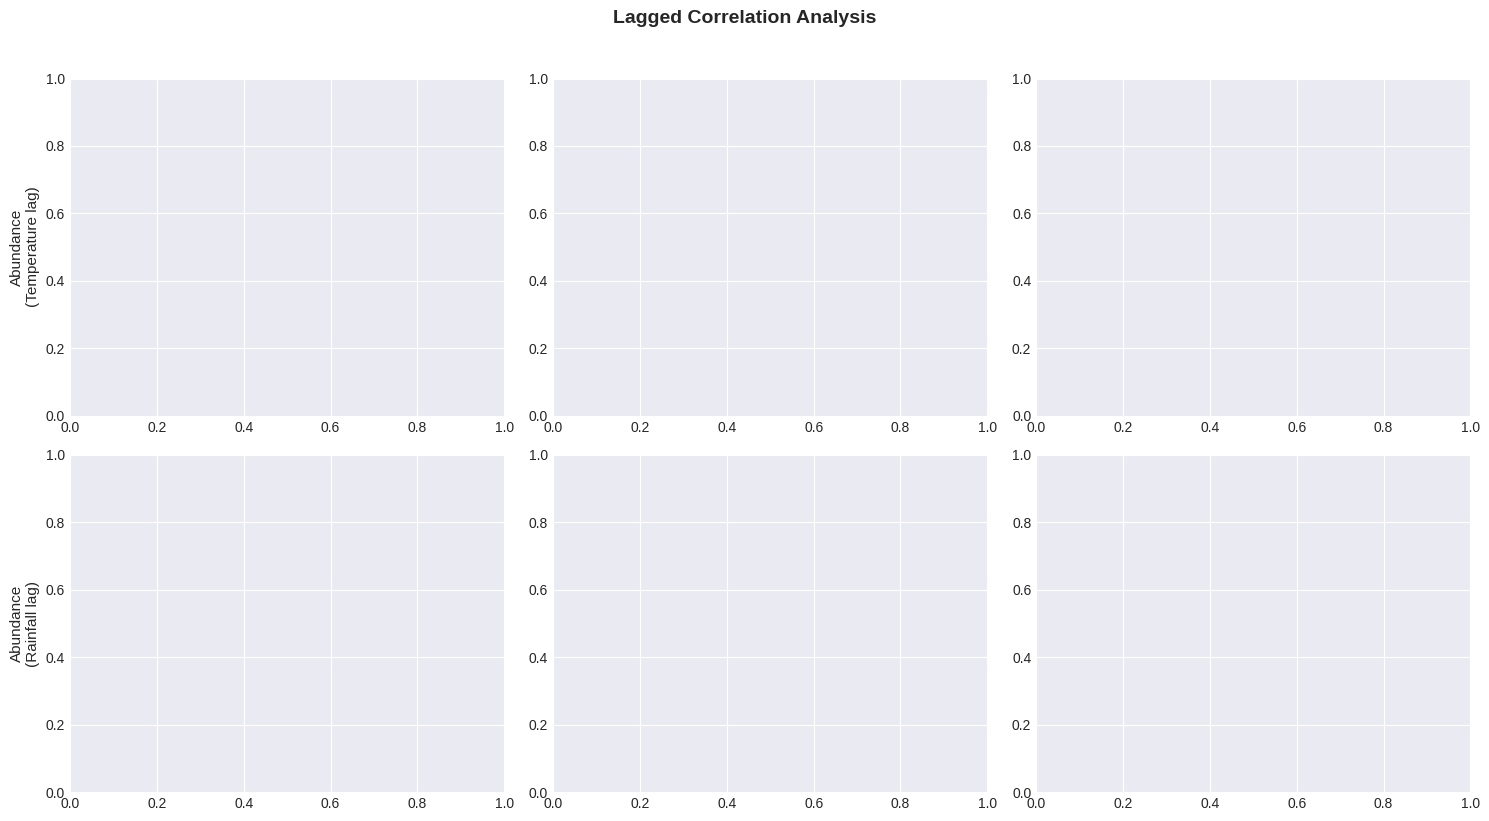

In [15]:
def analyze_lagged_correlations(df_merged, max_lag=3):
    """Analyze lagged correlations between climate variables and abundance."""
    
    fig, axes = plt.subplots(2, max_lag, figsize=(15, 8))
    
    lags = range(1, max_lag + 1)
    lag_correlations = {'temperature': [], 'rainfall': []}
    
    for i, lag in enumerate(lags):
        # Temperature lag
        df_temp_lag = df_merged[['temperature_mean_mean', 'total_count']].copy()
        df_temp_lag['temp_lag'] = df_temp_lag['temperature_mean_mean'].shift(lag)
        df_temp_clean = df_temp_lag.dropna()
        
        if len(df_temp_clean) > 1:
            corr_temp = df_temp_clean[['temp_lag', 'total_count']].corr().iloc[0, 1]
            lag_correlations['temperature'].append(corr_temp)
            
            axes[0, i].scatter(df_temp_clean['temp_lag'], df_temp_clean['total_count'],
                              alpha=0.7, s=80, color='#A23B72', edgecolors='black')
            axes[0, i].set_xlabel(f'Temperature (lag {lag} mo)', fontsize=10)
            axes[0, i].set_ylabel('Abundance', fontsize=10)
            axes[0, i].set_title(f'r = {corr_temp:.3f}', fontsize=11, fontweight='bold')
            axes[0, i].grid(True, alpha=0.3)
        
        # Rainfall lag
        df_rain_lag = df_merged[['rainfall_total_mean', 'total_count']].copy()
        df_rain_lag['rain_lag'] = df_rain_lag['rainfall_total_mean'].shift(lag)
        df_rain_clean = df_rain_lag.dropna()
        
        if len(df_rain_clean) > 1:
            corr_rain = df_rain_clean[['rain_lag', 'total_count']].corr().iloc[0, 1]
            lag_correlations['rainfall'].append(corr_rain)
            
            axes[1, i].scatter(df_rain_clean['rain_lag'], df_rain_clean['total_count'],
                              alpha=0.7, s=80, color='#F18F01', edgecolors='black')
            axes[1, i].set_xlabel(f'Rainfall (lag {lag} mo)', fontsize=10)
            axes[1, i].set_ylabel('Abundance', fontsize=10)
            axes[1, i].set_title(f'r = {corr_rain:.3f}', fontsize=11, fontweight='bold')
            axes[1, i].grid(True, alpha=0.3)
    
    axes[0, 0].set_ylabel('Abundance\n(Temperature lag)', fontsize=11)
    axes[1, 0].set_ylabel('Abundance\n(Rainfall lag)', fontsize=11)
    
    plt.suptitle('Lagged Correlation Analysis', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return lag_correlations

lag_correlations = analyze_lagged_correlations(df_merged)


#### 7. Spatial Distribution Map

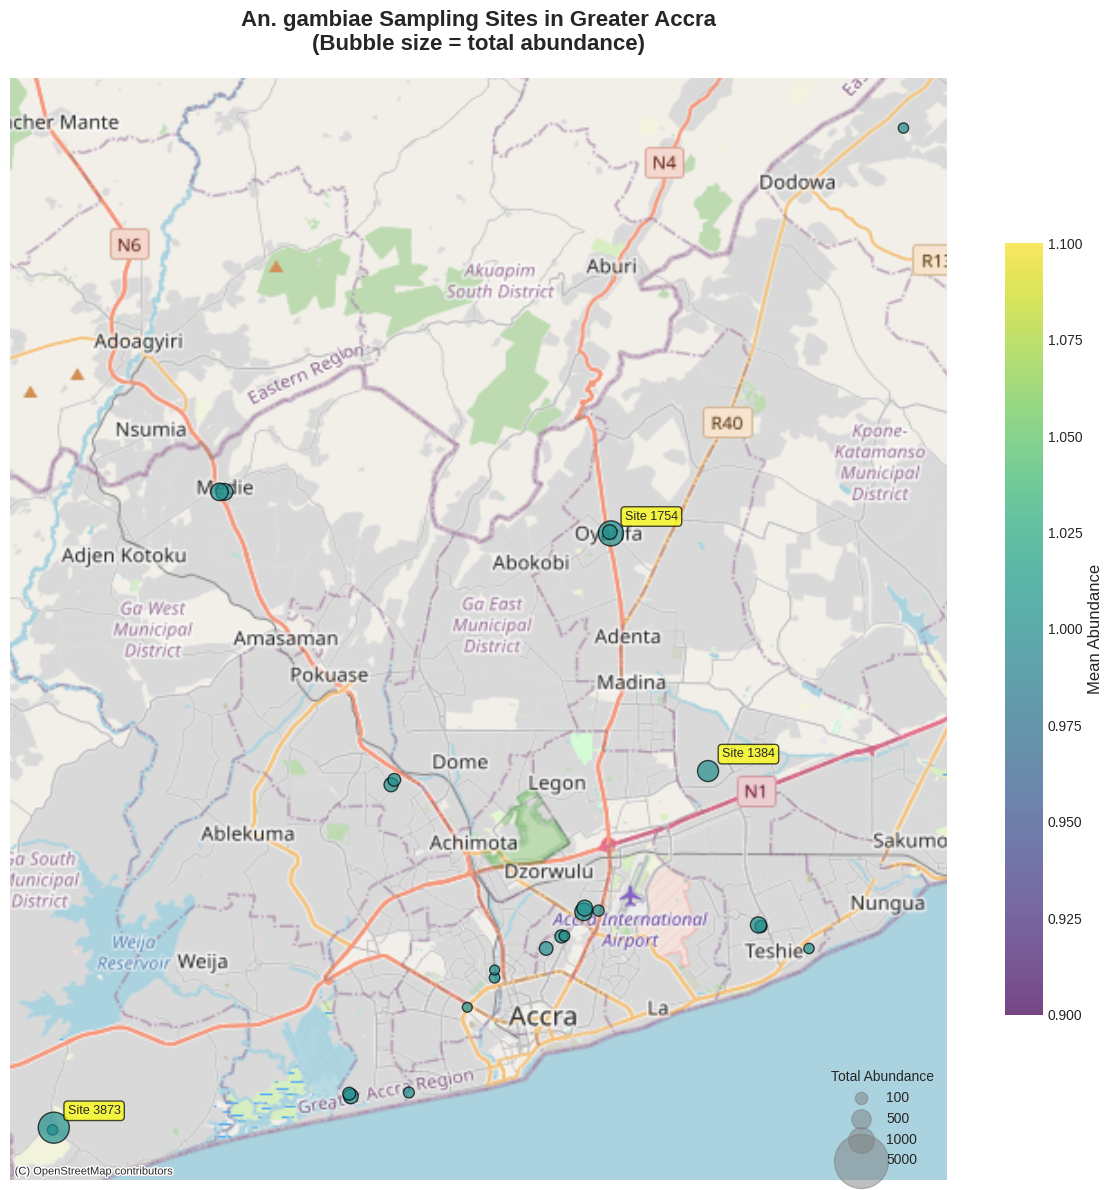

In [16]:
def create_sampling_map(gdf_accra):
    """Create a map of sampling sites with abundance."""
    
    # Aggregate by site
    df_sites = gdf_accra.groupby(['location_code', 'lat', 'lon'], as_index=False)['count'].agg(['sum', 'mean', 'count'])
    df_sites.columns = ['location_code', 'lat', 'lon', 'total_abundance', 'mean_abundance', 'n_observations']
    
    gdf_sites = gpd.GeoDataFrame(
        df_sites,
        geometry=gpd.points_from_xy(df_sites['lon'], df_sites['lat']),
        crs='EPSG:4326'
    )
    
    # Convert to Web Mercator for basemap
    gdf_sites_3857 = gdf_sites.to_crs(epsg=3857)
    
    # Create map
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Scale bubble sizes
    min_size = 50
    max_size = 500
    sizes = min_size + (gdf_sites_3857['total_abundance'] / gdf_sites_3857['total_abundance'].max()) * (max_size - min_size)
    
    # Plot sites
    scatter = ax.scatter(
        gdf_sites_3857.geometry.x,
        gdf_sites_3857.geometry.y,
        s=sizes,
        c=gdf_sites_3857['mean_abundance'],
        cmap='viridis',
        alpha=0.7,
        edgecolors='black',
        linewidth=1
    )
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
    cbar.set_label('Mean Abundance', fontsize=12)
    
    # Add basemap
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
    
    # Add annotations for sites with highest abundance
    top_sites = gdf_sites_3857.nlargest(3, 'total_abundance')
    for idx, row in top_sites.iterrows():
        ax.annotate(
            f'Site {row["location_code"][-4:]}',
            (row.geometry.x, row.geometry.y),
            xytext=(10, 10),
            textcoords='offset points',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7)
        )
    
    ax.set_title('An. gambiae Sampling Sites in Greater Accra\n(Bubble size = total abundance)', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.set_axis_off()
    
    # Add legend for bubble sizes
    legend_elements = []
    for size in [100, 500, 1000, 5000]:
        legend_elements.append(plt.scatter([], [], s=min_size + (size / df_sites['total_abundance'].max()) * (max_size - min_size),
                                          c='gray', alpha=0.5, label=f'{size}'))
    ax.legend(handles=legend_elements, loc='lower right', title='Total Abundance')
    
    plt.tight_layout()
    plt.show()
    
    return gdf_sites

gdf_sites = create_sampling_map(gdf_accra)


#### 8. Summary Statistics and Interpretation

In [17]:
def generate_summary_stats(df_merged, gdf_sites, corr_matrix, lag_correlations):
    """Generate comprehensive summary statistics."""
    
    print("=" * 60)
    print("SUMMARY STATISTICS")
    print("=" * 60)
    
    print(f"\nData Overview:")
    print(f"- Total sampling months: {len(df_merged)}")
    print(f"- Total sampling sites: {len(gdf_sites)}")
    print(f"- Total observations: {gdf_sites['n_observations'].sum()}")
    
    print(f"\nVector Abundance:")
    print(f"- Mean monthly abundance: {df_merged['total_count'].mean():.1f} (±{df_merged['total_count'].std():.1f})")
    print(f"- Peak abundance: {df_merged['total_count'].max()} (month: {df_merged.loc[df_merged['total_count'].idxmax(), 'date_id']})")
    print(f"- Lowest abundance: {df_merged['total_count'].min()} (month: {df_merged.loc[df_merged['total_count'].idxmin(), 'date_id']})")
    
    print(f"\nEnvironmental Conditions:")
    print(f"- Mean temperature: {df_merged['temperature_mean_mean'].mean():.1f}°C (±{df_merged['temperature_mean_mean'].std():.1f})")
    print(f"- Mean rainfall: {df_merged['rainfall_total_mean'].mean():.1f} mm (±{df_merged['rainfall_total_mean'].std():.1f})")
    
    print(f"\nCorrelations with Abundance:")
    print(f"- Temperature: r = {corr_matrix.loc['total_count', 'temperature_mean_mean']:.3f}")
    print(f"- Rainfall: r = {corr_matrix.loc['total_count', 'rainfall_total_mean']:.3f}")
    
    print(f"\nLagged Correlations:")
    for lag in range(1, 4):
        if lag <= len(lag_correlations['temperature']):
            print(f"- Temperature (lag {lag}): r = {lag_correlations['temperature'][lag-1]:.3f}")
            print(f"- Rainfall (lag {lag}): r = {lag_correlations['rainfall'][lag-1]:.3f}")
    
    print(f"\nTop 5 Sampling Sites by Abundance:")
    print(gdf_sites.nlargest(5, 'total_abundance')[['location_code', 'total_abundance', 'mean_abundance', 'n_observations']].to_string(index=False))
    
    print("\n" + "=" * 60)

generate_summary_stats(df_merged, gdf_sites, corr_matrix, lag_correlations)


SUMMARY STATISTICS

Data Overview:
- Total sampling months: 2
- Total sampling sites: 25
- Total observations: 6156

Vector Abundance:
- Mean monthly abundance: 153.0 (±35.4)
- Peak abundance: 178 (month: 2024-01-01)
- Lowest abundance: 128 (month: 2025-01-01)

Environmental Conditions:
- Mean temperature: 29.2°C (±0.1)
- Mean rainfall: 0.5 mm (±0.0)

Correlations with Abundance:
- Temperature: r = 1.000
- Rainfall: r = -1.000

Lagged Correlations:

Top 5 Sampling Sites by Abundance:
       location_code  total_abundance  mean_abundance  n_observations
point_5_5139_n0_3873             1536             1.0            1536
point_5_7441_n0_1754              946             1.0             946
point_5_6521_n0_1384              612             1.0             612
point_5_5975_n0_1857              376             1.0             376
point_5_7602_n0_3243              370             1.0             370

